# RQ3 Analysis: Lexical Density

Compares lexical density of human-written PR descriptions and AI-generated descriptions across six context variations.

- Models: `meta-llama/llama-3.1-70b-instruct`, `gpt-5-mini-2025-08-07`, `Qwen/Qwen2.5-72B-Instruct`
- Formula: `Lexical Density = content_words / total_tokens`
- Content POS tags: `NOUN`, `PROPN`, `VERB`, `ADJ`, `ADV`
- POS tagging: spaCy `en_core_web_sm`

In [1]:
import spacy
nlp = spacy.load('en_core_web_sm')


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from pathlib import Path
from scipy.stats import mannwhitneyu, kruskal
import paired_stats as PS  # Tier-A shared helpers: paired Wilcoxon, FDR, effect sizes
import scikit_posthocs as sp

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)


## 1. Data Loading & Preparation

In [3]:
CONTEXT_MAPPING = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}

TARGET_MODELS = [
    'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct'
 ]

csv_path = Path('..') / 'datasets' / 'temperature_1' / 'run_3_cleaned' / 'detection_results.csv'
df = pd.read_csv(csv_path, usecols=['pr_id', 'entry_type', 'variation', 'model', 'text']).copy()

# Normalize model names to canonical labels used in this notebook
model_aliases = {
    'meta-llama_llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'meta-llama/llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07': 'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen/Qwen2.5-72B-Instruct'
}
df['model'] = df['model'].astype(str).str.strip().map(lambda m: model_aliases.get(m, m))

ai_df = df[(df['entry_type'] == 'ai') & (df['model'].isin(TARGET_MODELS))].copy()
ai_df = ai_df[ai_df['variation'].isin(CONTEXT_MAPPING.keys())].copy()
ai_df['context_level'] = ai_df['variation']
ai_df['Context_Name'] = ai_df['variation'].map(CONTEXT_MAPPING)
ai_df['normalized_pr_id'] = ai_df['pr_id'].astype(str).str.strip()

human_df = df[df['entry_type'] == 'human'].copy()
human_df['model'] = 'Human'
human_df['context_level'] = 'Original'
human_df['Context_Name'] = 'Original'
human_df['normalized_pr_id'] = human_df['pr_id'].astype(str).str.strip()

valid_ids = set(ai_df['normalized_pr_id']).intersection(set(human_df['normalized_pr_id']))
ai_df = ai_df[ai_df['normalized_pr_id'].isin(valid_ids)].copy()
human_df = human_df[human_df['normalized_pr_id'].isin(valid_ids)].copy()

print(f'Data source: {csv_path}')
print(f'Paired PR count: {len(valid_ids)}')
print('Models found:', sorted(ai_df['model'].unique().tolist()))
print('Contexts found:', sorted(ai_df['variation'].unique().tolist()))
print(f'Human rows: {len(human_df)}, AI rows: {len(ai_df)}')

Data source: ../datasets/temperature_1/run_3_cleaned/detection_results.csv
Paired PR count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
Contexts found: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Human rows: 308, AI rows: 5526


## 2. Compute Lexical Density (spaCy POS)


In [4]:
CONTENT_POS = {'NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV'}

def lexical_density(text: str) -> float:
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    doc = nlp(str(text))
    tokens = [t for t in doc if not t.is_punct and not t.is_space]
    if len(tokens) == 0:
        return np.nan
    content_words = sum(1 for t in tokens if t.pos_ in CONTENT_POS)
    return content_words / len(tokens)

human_df['lexical_density'] = human_df['text'].apply(lexical_density)
ai_df['lexical_density'] = ai_df['text'].apply(lexical_density)
human_df['source'] = 'Human'
ai_df['source'] = 'AI'
combined_df = pd.concat([human_df, ai_df], ignore_index=True)


## 3. Descriptive Statistics

In [5]:
overall_stats = combined_df.groupby('source')['lexical_density'].describe()
overall_stats['median'] = combined_df.groupby('source')['lexical_density'].median()
display(overall_stats)

model_stats = ai_df.groupby('model')['lexical_density'].describe()
model_stats['median'] = ai_df.groupby('model')['lexical_density'].median()
display(model_stats)

context_stats = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].describe()
context_stats['median'] = ai_df.groupby(['model', 'Context_Name'])['lexical_density'].median()
display(context_stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5526.0,0.643013,0.079813,0.426316,0.583333,0.642857,0.700000,1.0,0.642857
Human,308.0,0.568896,0.073314,0.350000,0.511462,0.556349,0.613249,1.0,0.556349


,count,mean,std,min,25%,50%,75%,max,median
model,,,,,,,,,
Qwen/Qwen2.5-72B-Instruct,1842.0,0.582801,0.054696,0.426316,0.544444,0.579193,0.618891,0.746667,0.579193
gpt-5-mini-2025-08-07,1842.0,0.690882,0.049264,0.525862,0.656627,0.691228,0.724023,0.849057,0.691228
meta-llama/llama-3.1-70b-instruct,1842.0,0.655355,0.087329,0.428571,0.592593,0.647059,0.714286,1.000000,0.647059


count      mean  \
model                             Context_Name                             
Qwen/Qwen2.5-72B-Instruct         File Contents          302.0  0.614348   
                                  File Diff              308.0  0.566109   
                                  Linked Issue           308.0  0.559653   
                                  PR Title               308.0  0.617616   
                                  Repo Path              308.0  0.583653   
                                  Without File Contents  308.0  0.556044   
gpt-5-mini-2025-08-07             File Contents          302.0  0.721449   
                                  File Diff              308.0  0.696825   
                                  Linked Issue           308.0  0.649957   
                                  PR Title               308.0  0.684983   
                                  Repo Path              308.0  0.710389   
                                  Without File Contents  308.0  0.682281   
meta-llama/llama-3.1-70b-instruct File Contents          302.0  0.696406   
                                  File Diff              308.0  0.680019   
                                  Linked Issue           308.0  0.608939   
                                  PR Title               308.0  0.640787   
                                  Repo Path              308.0  0.712223   
                                  Without File Contents  308.0  0.594557   

                                                              std       min  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.054273  0.447059   
                                  File Diff              0.049295  0.426316   
                                  Linked Issue           0.042796  0.430556   
                                  PR Title               0.049300  0.454545   
                                  Repo Path              0.051083  0.471264   
                                  Without File Contents  0.044941  0.454545   
gpt-5-mini-2025-08-07             File Contents          0.047822  0.573171   
                                  File Diff              0.050710  0.540541   
                                  Linked Issue           0.039747  0.525862   
                                  PR Title               0.038380  0.595745   
                                  Repo Path              0.038135  0.613861   
                                  Without File Contents  0.045903  0.569231   
meta-llama/llama-3.1-70b-instruct File Contents          0.072914  0.444444   
                                  File Diff              0.080387  0.428571   
                                  Linked Issue           0.068048  0.442308   
                                  PR Title               0.065427  0.448980   
                                  Repo Path              0.093558  0.465116   
                                  Without File Contents  0.069278  0.437500   

                                                              25%       50%  \
model                             Context_Name                                
Qwen/Qwen2.5-72B-Instruct         File Contents          0.579783  0.613270   
                                  File Diff              0.533333  0.565396   
                                  Linked Issue           0.532650  0.557377   
                                  PR Title               0.585366  0.617914   
                                  Repo Path              0.545455  0.581450   
                                  Without File Contents  0.527423  0.553709   
gpt-5-mini-2025-08-07             File Contents          0.690898  0.723970   
                                  File Diff              0.660630  0.699465   
                                  Linked Issue           0.624594  0.649848   
                                  PR Title               0.656209  0.687310   
       

## 4. Statistical Testing & Effect Size

In [6]:
# Per-model OVERALL comparison (PAIRED, per-PR mean across contexts) -- Tier-A.
# Replaces independent-samples Mann-Whitney U on paired human/AI data. For each model,
# summarise its six-context output per PR as the mean, then pair against the human value
# for the same PR (Wilcoxon signed-rank). Effect sizes: Cliff's delta (dominance) +
# matched-pairs rank-biserial. FDR (BH) applied within each metric. See paired_stats.py.
models = ai_df['model'].unique()
model_results = []
for _col, _label in [('lexical_density', 'Lexical Density')]:
    _ai_all = ai_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _hu_all = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _m = pd.concat([_hu_all.rename('h'), _ai_all.rename('a')], axis=1, join='inner').dropna()
    _r = PS.paired_test(_m['h'].values, _m['a'].values)
    print("[%s] pooled Human vs AI (paired): n=%d, Wilcoxon p=%.3g, Cliff's d=%.4f (%s)"
          % (_label, _r['n'], _r['p'], _r['cliffs_delta'], _r['magnitude']))
    for _model in ai_df['model'].unique():
        _ai_pr = ai_df[ai_df['model'] == _model].dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _hu_pr = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _merged = pd.concat([_hu_pr.rename('h'), _ai_pr.rename('a')], axis=1, join='inner').dropna()
        _r = PS.paired_test(_merged['h'].values, _merged['a'].values)
        model_results.append({
            'Model': _model, 'Metric': _label, 'N pairs': _r['n'],
            'Human Median': _r['median_human'], 'Model Median': _r['median_ai'],
            'Wilcoxon p': _r['p'], "Cliff's Delta": round(_r['cliffs_delta'], 4),
            'Rank-Biserial': round(_r['rank_biserial'], 4), 'Effect Size': _r['magnitude'],
        })
model_results_df = pd.DataFrame(model_results)
model_results_df = PS.apply_fdr_by(model_results_df, 'Metric', pcol='Wilcoxon p')
model_results_df['Sig'] = model_results_df['adj_Wilcoxon p'].apply(PS.sig_mark)
display(model_results_df)


[Lexical Density] pooled Human vs AI (paired): n=308, Wilcoxon p=1.43e-37, Cliff's d=-0.6835 (Large)


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,meta-llama/llama-3.1-70b-instruct,Lexical Density,308,0.556349,0.655325,2.599860e-41,-0.7267,-0.8851,Large,3.899790e-41,True,***
1,gpt-5-mini-2025-08-07,Lexical Density,308,0.556349,0.689843,2.716448e-47,-0.8845,-0.9496,Large,8.149343e-47,True,***
2,Qwen/Qwen2.5-72B-Instruct,Lexical Density,308,0.556349,0.582617,1.378378e-05,-0.2485,-0.2858,Small,1.378378e-05,True,***


## 5. Visualizations

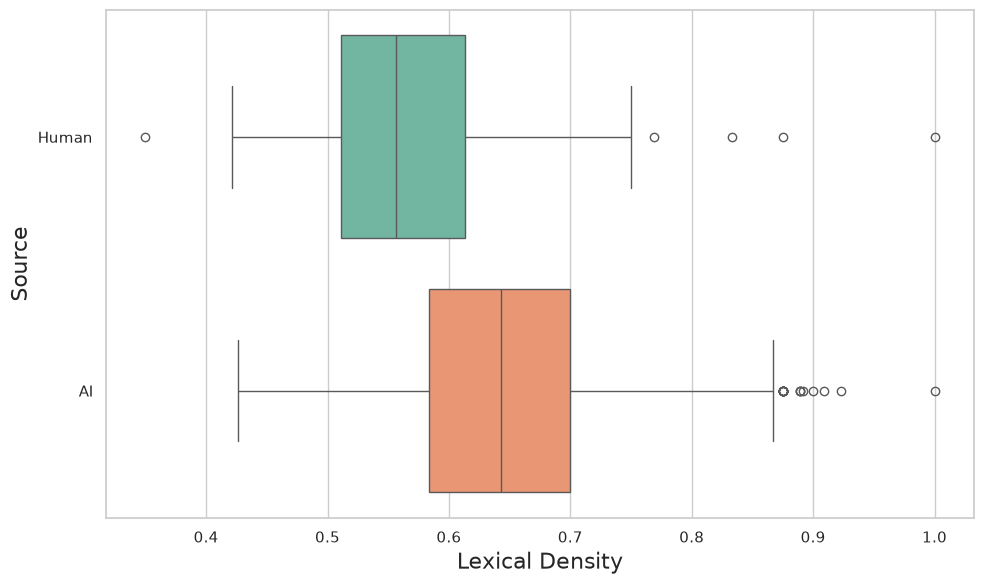

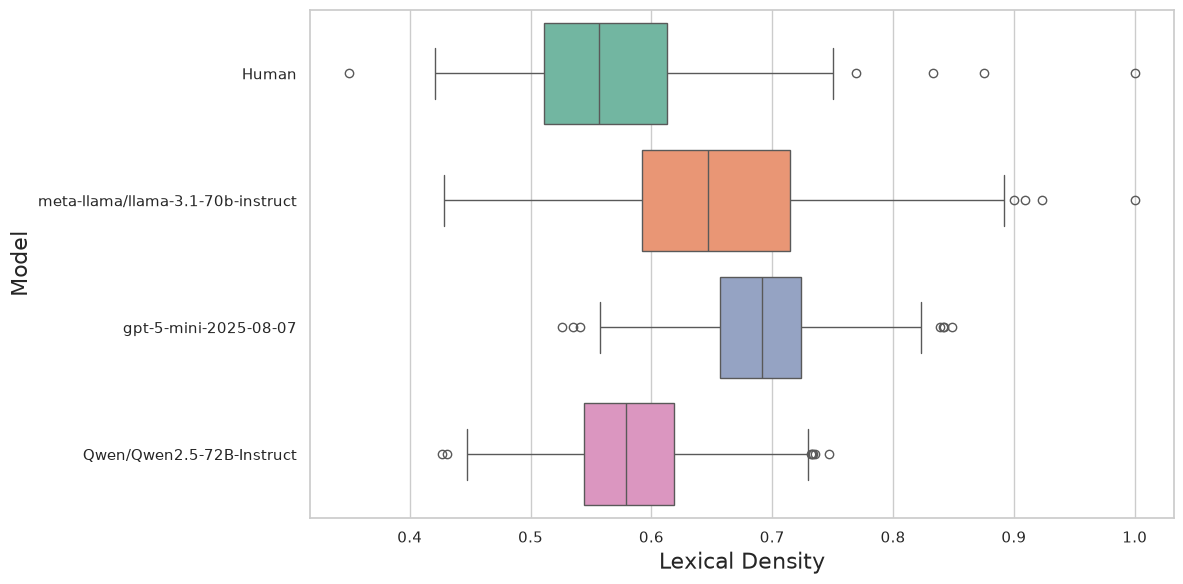

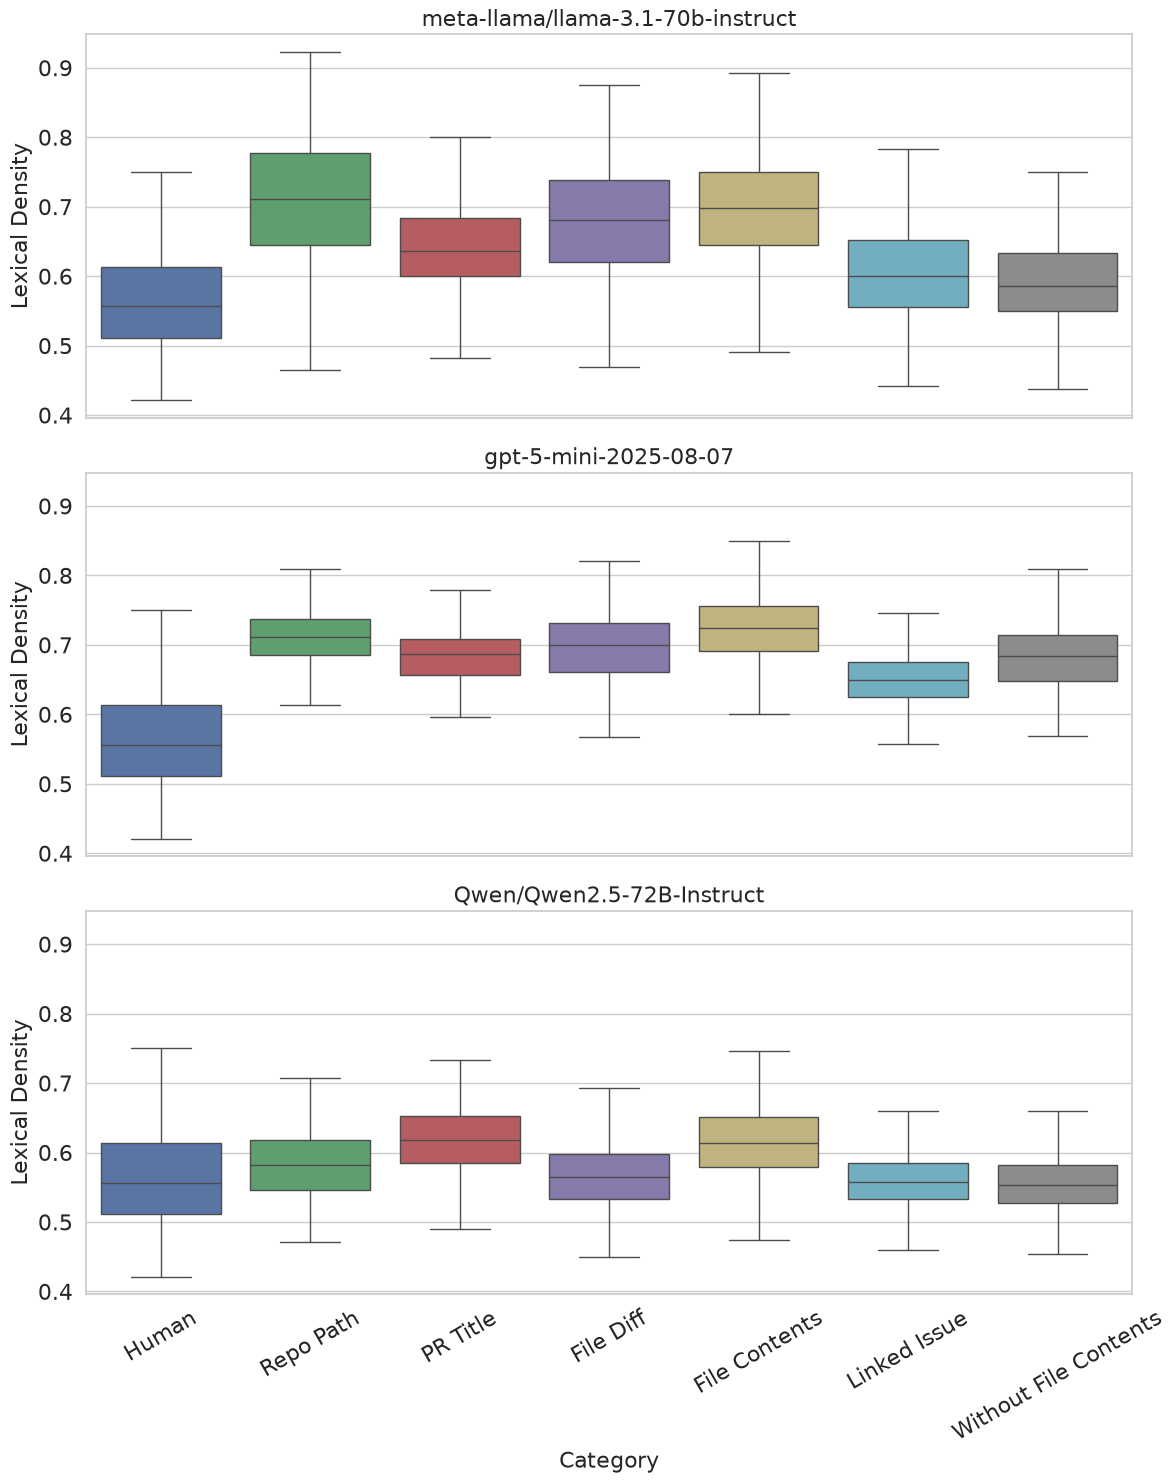

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='lexical_density', y='source', hue='source', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=16)
plt.ylabel('Source', fontsize=16)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
model_plot_df = combined_df.copy()
order = ['Human'] + TARGET_MODELS
sns.boxplot(data=model_plot_df, x='lexical_density', y='model', order=order, hue='model', palette='Set2', legend=False)
plt.xlabel('Lexical Density', fontsize=16)
plt.ylabel('Model', fontsize=16)
plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

# Context comparison in the same style as other RQ3 notebooks:
# one panel per LLM (stacked vertically) with a Human baseline in each panel.
context_order = [CONTEXT_MAPPING[k] for k in ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']]
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    context_order[0]: '#55A868',
    context_order[1]: '#C44E52',
    context_order[2]: '#8172B2',
    context_order[3]: '#CCB974',
    context_order[4]: '#64B5CD',
    context_order[5]: '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    ai_slice = ai_df[ai_df['model'] == model][['lexical_density', 'Context_Name']].dropna().copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['lexical_density']].dropna().copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['lexical_density', 'Category']],
        ai_slice[['lexical_density', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='lexical_density',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('Lexical Density', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'lexical_density.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 6. Human vs AI Context Variations (Cliff's δ per Model)

In [8]:
# Human vs. AI per context (PAIRED): Cliff's delta + Wilcoxon signed-rank, BH-FDR -- Tier-A.
# Filter by the stable variation code (P-1..P-6); display labels differ across notebooks
# ('File Diff' vs 'PR Diffs', 'Linked Issue' vs 'Related Issues'), so the code is the safe key.
import os as _os
VARIATION_TO_CTX = {'P-1': 'Repo Path', 'P-2': 'PR Title', 'P-3': 'File Diff', 'P-4': 'File Contents', 'P-5': 'Linked Issue', 'P-6': 'Without File Contents'}
variation_codes = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
variation_names = [VARIATION_TO_CTX[_p] for _p in variation_codes]
_long = []
for _col, _label in [('lexical_density', 'Lexical Density')]:
    for _model in ai_df['model'].unique():
        for _pcode in variation_codes:
            _slice = ai_df[(ai_df['model'] == _model) & (ai_df['variation'] == _pcode)]
            _r = PS.paired_test_from_frames(human_df, _slice, _col, key='normalized_pr_id')
            _long.append({'Metric': _label, 'Model': _model, 'Context': VARIATION_TO_CTX[_pcode],
                          'n': _r['n'], 'cliffs_delta': _r['cliffs_delta'], 'magnitude': _r['magnitude'],
                          'rank_biserial': _r['rank_biserial'], 'p': _r['p']})
long_df = PS.apply_fdr_by(pd.DataFrame(_long), 'Metric', pcol='p')
long_df['Sig'] = long_df['adj_p'].apply(PS.sig_mark)
_os.makedirs('outputs', exist_ok=True)
long_df.to_csv('outputs/rq2_lexical_density_paired_stats.csv', index=False)
print('Saved tidy paired stats -> outputs/rq2_lexical_density_paired_stats.csv')

def _fmt_cell(x):
    return "%.3f (%s) %s" % (x['cliffs_delta'], x['magnitude'][0], x['Sig'])
context_tables = {}
for _col, _label in [('lexical_density', 'Lexical Density')]:
    _sub = long_df[long_df['Metric'] == _label].copy()
    _sub['cell'] = _sub.apply(_fmt_cell, axis=1)
    _piv = _sub.pivot(index='Model', columns='Context', values='cell').reindex(columns=variation_names)
    context_tables[_label] = _piv
    print("\n=== %s: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===" % _label)
    display(_piv)
result_df = list(context_tables.values())[-1]
effect_df = list(context_tables.values())[-1]


Saved tidy paired stats -> outputs/rq2_lexical_density_paired_stats.csv

=== Lexical Density: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,-0.198 (S) ***,-0.472 (M) ***,-0.044 (N) n.s.,-0.444 (M) ***,0.005 (N) n.s.,0.047 (N) *
gpt-5-mini-2025-08-07,-0.908 (L) ***,-0.841 (L) ***,-0.849 (L) ***,-0.913 (L) ***,-0.690 (L) ***,-0.816 (L) ***
meta-llama/llama-3.1-70b-instruct,-0.775 (L) ***,-0.570 (L) ***,-0.709 (L) ***,-0.793 (L) ***,-0.349 (M) ***,-0.243 (S) ***


## 7. Summary Table & Export

In [9]:
summary_rows = []
for model in ['Human'] + TARGET_MODELS:
    vals = combined_df[combined_df['model'] == model]['lexical_density'].dropna()
    summary_rows.append({
        'Model': model,
        'Metric': 'Lexical Density',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

out_dir = Path('outputs')
out_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(out_dir / 'rq3_lexical_density_summary.csv', index=False)
effect_df.reset_index().to_csv(out_dir / 'rq3_lexical_density_cliffs_delta_by_context.csv', index=False)
model_results_df.to_csv(out_dir / 'rq3_lexical_density_human_vs_model_stats.csv', index=False)
print('Saved outputs to outputs/.')
print('- rq3_lexical_density_summary.csv')
print('- rq3_lexical_density_cliffs_delta_by_context.csv')
print('- rq3_lexical_density_human_vs_model_stats.csv')

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Lexical Density,308,0.5689,0.5563,0.0733,0.3500,1.0000,0.5115,0.6132
1,meta-llama/llama-3.1-70b-instruct,Lexical Density,1842,0.6554,0.6471,0.0873,0.4286,1.0000,0.5926,0.7143
2,gpt-5-mini-2025-08-07,Lexical Density,1842,0.6909,0.6912,0.0493,0.5259,0.8491,0.6566,0.7240
3,Qwen/Qwen2.5-72B-Instruct,Lexical Density,1842,0.5828,0.5792,0.0547,0.4263,0.7467,0.5444,0.6189


Saved outputs to outputs/.
- rq3_lexical_density_summary.csv
- rq3_lexical_density_cliffs_delta_by_context.csv
- rq3_lexical_density_human_vs_model_stats.csv
